# Aula 09 - EDA: Detec??o de fraudes
Kubeflow Pipelines | Kaggle Credit Card Fraud Detection

Execu??o dentro do cluster Kubernetes.

## 1. Instala??o do XGBoost

In [1]:
import xgboost as xgb
print('XGBoost CPU:', xgb.__version__)

XGBoost CPU: 3.2.0


## 2. Bibliotecas e vers?es

In [2]:

import sys
from pathlib import Path

sys.path.insert(0, '/home/jovyan/work')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb

sns.set_theme(style='whitegrid')

print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('xgboost:', xgb.__version__)


pandas: 2.2.2
numpy: 1.26.4
xgboost: 3.2.0


## 3. Carregamento do dataset

In [3]:

arquivo = Path('/home/jovyan/data/creditcard.csv')

assert arquivo.exists(), 'CSV nao encontrado no PVC'

df = pd.read_csv(arquivo)

print('Shape:', df.shape)
print('Valores ausentes:', df.isna().sum().sum())

display(df.head())


Shape: (284807, 31)
Valores ausentes: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 4. Tipos e estat?sticas descritivas

In [4]:

display(df.dtypes)
display(df.describe())


Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## 5. Desbalanceamento da vari?vel alvo

Class
0    284315
1       492
Name: count, dtype: int64
legitima: 284315 (99.8273%)
fraude: 492 (0.1727%)


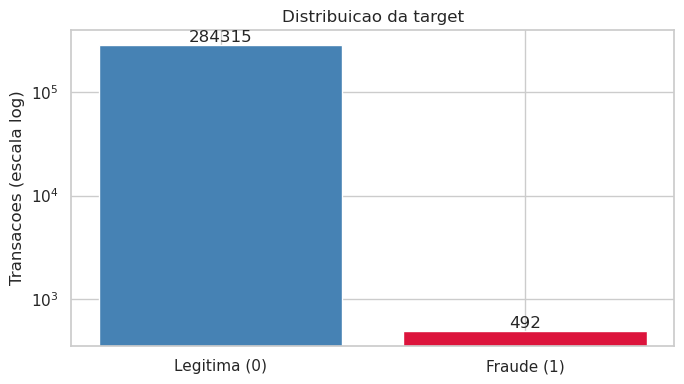

In [5]:

class_counts = df['Class'].value_counts().sort_index()

print(class_counts)

for cls, n in class_counts.items():
    label = 'legitima' if cls == 0 else 'fraude'
    pct = 100 * n / len(df)
    print(f'{label}: {n} ({pct:.4f}%)')

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    ['Legitima (0)', 'Fraude (1)'],
    class_counts.values,
    color=['steelblue', 'crimson']
)

ax.set_yscale('log')
ax.set_ylabel('Transacoes (escala log)')
ax.set_title('Distribuicao da target')

for i, v in enumerate(class_counts.values):
    ax.text(i, v, str(v), ha='center', va='bottom')

plt.tight_layout()
plt.show()


## 6. Distribui??o de Amount

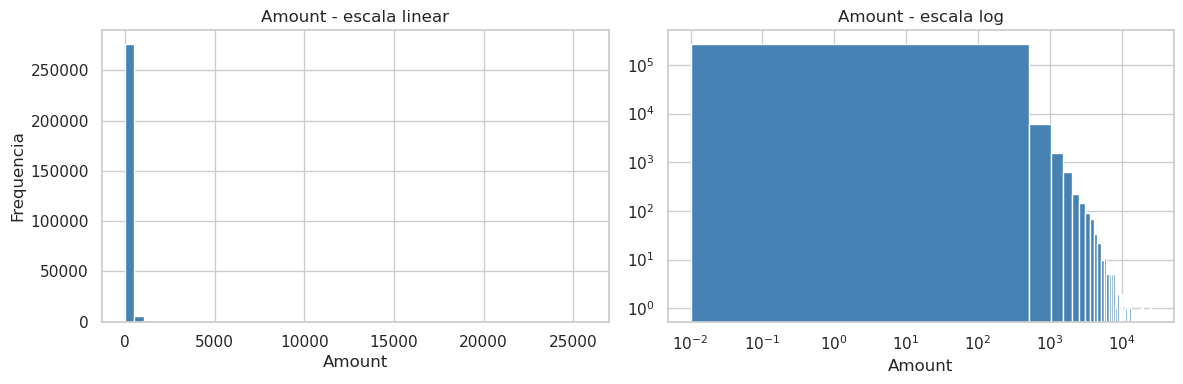

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [6]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

amount = df['Amount'].to_numpy()

axes[0].hist(amount, bins=50, color='steelblue')
axes[0].set_title('Amount - escala linear')
axes[0].set_xlabel('Amount')
axes[0].set_ylabel('Frequencia')

axes[1].hist(
    amount[amount > 0],
    bins=50,
    color='steelblue'
)

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Amount - escala log')
axes[1].set_xlabel('Amount')

plt.tight_layout()
plt.show()

display(df['Amount'].describe())


## 7. Correla??o das vari?veis com fraude

V17   -0.326
V14   -0.303
V12   -0.261
V10   -0.217
V16   -0.197
V3    -0.193
V7    -0.187
V11    0.155
V4     0.133
V18   -0.111
dtype: float64

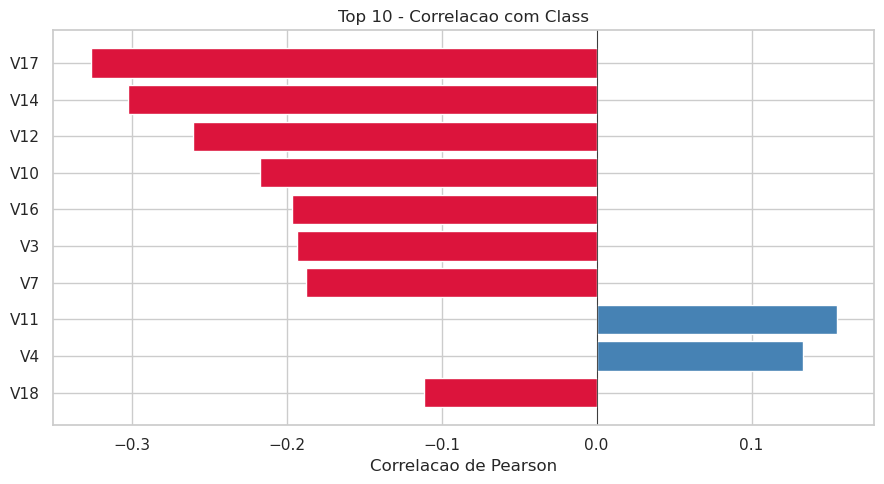

In [7]:

v_columns = [f'V{i}' for i in range(1, 29)]

correlations = df[v_columns + ['Amount']].corrwith(
    df['Class']
)

top_corr = correlations.abs().sort_values(
    ascending=False
).head(10)

top_corr_signed = correlations.loc[top_corr.index]

display(top_corr_signed.round(3))

fig, ax = plt.subplots(figsize=(9, 5))

colors = [
    'crimson' if v < 0 else 'steelblue'
    for v in top_corr_signed
]

ax.barh(
    top_corr_signed.index[::-1],
    top_corr_signed.values[::-1],
    color=colors[::-1]
)

ax.axvline(0, color='black', linewidth=0.5)
ax.set_title('Top 10 - Correlacao com Class')
ax.set_xlabel('Correlacao de Pearson')

plt.tight_layout()
plt.show()


## 8. Fraudes por quartil de Amount

In [8]:

df_seg = df.assign(
    amount_quartil=pd.qcut(
        df['Amount'],
        q=4,
        labels=['Q1', 'Q2', 'Q3', 'Q4']
    )
)

fraud_por_quartil = (
    df_seg.groupby('amount_quartil', observed=True)['Class']
    .agg(['count', 'sum', 'mean'])
    .rename(columns={
        'count': 'n_transacoes',
        'sum': 'n_fraudes',
        'mean': 'fraud_rate'
    })
)

display(fraud_por_quartil)


,n_transacoes,n_fraudes,fraud_rate
amount_quartil,,,
Q1,71241,224,0.003144
Q2,71402,47,0.000658
Q3,70962,47,0.000662
Q4,71202,174,0.002444


## 9. Segmenta??o em low, medium e high

In [9]:

df_seg = df.assign(
    amount_segment=pd.qcut(
        df['Amount'],
        q=[0, 0.25, 0.75, 1],
        labels=['low', 'medium', 'high']
    )
)

fraud_rate = (
    df_seg.groupby('amount_segment', observed=True)['Class']
    .agg(['count', 'sum', 'mean'])
    .rename(columns={
        'count': 'n_transacoes',
        'sum': 'n_fraudes',
        'mean': 'fraud_rate'
    })
)

display(fraud_rate)

assert fraud_rate['n_transacoes'].sum() == len(df)
assert fraud_rate['n_fraudes'].sum() == int(df['Class'].sum())


,n_transacoes,n_fraudes,fraud_rate
amount_segment,,,
low,71241,224,0.003144
medium,142364,94,0.000660
high,71202,174,0.002444


## 10. Estrat?gia de modelagem

A proposta da aula ? experimentar tr?s modelos XGBoost:

- low: transa??es de menor valor
- medium: transa??es intermedi?rias
- high: transa??es de maior valor

Na modelagem, os limites dos segmentos dever?o ser calculados somente com os dados de treinamento para evitar vazamento de informa??es.

Tamb?m ser? necess?rio comparar os tr?s modelos com uma abordagem de modelo ?nico e usar m?tricas adequadas ao desbalanceamento.

## 11. Verifica??o final

In [10]:

assert df.shape == (284807, 31)
assert int(df['Class'].sum()) == 492
assert df.isna().sum().sum() == 0

print('EDA VALIDADA COM SUCESSO')
print('REGISTROS:', len(df))
print('FRAUDES:', int(df['Class'].sum()))
print('SEGMENTOS:', list(fraud_rate.index.astype(str)))


EDA VALIDADA COM SUCESSO
REGISTROS: 284807
FRAUDES: 492
SEGMENTOS: ['low', 'medium', 'high']
